<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Corpus length: 6700 | Vocab size: 32 | Sequences: 2224

=== Training Summary Across Clipping Settings (LR = 0.25) ===
No Clipping      | Steps:   2 | Spike Step: 1    | NaN Step: 2    | Final Loss: NaN
clipnorm = 1.0   | Steps: 120 | Spike Step: None | NaN Step: None | Final Loss: 2.9178
clipnorm = 5.0   | Steps: 120 | Spike Step: None | NaN Step: None | Final Loss: 3.2335
clipvalue = 0.5  | Steps: 120 | Spike Step: 1    | NaN Step: None | Final Loss: 2.1966
clipvalue = 1.0  | Steps: 120 | Spike Step: 1    | NaN Step: None | Final Loss: 218074427056440999936.0000


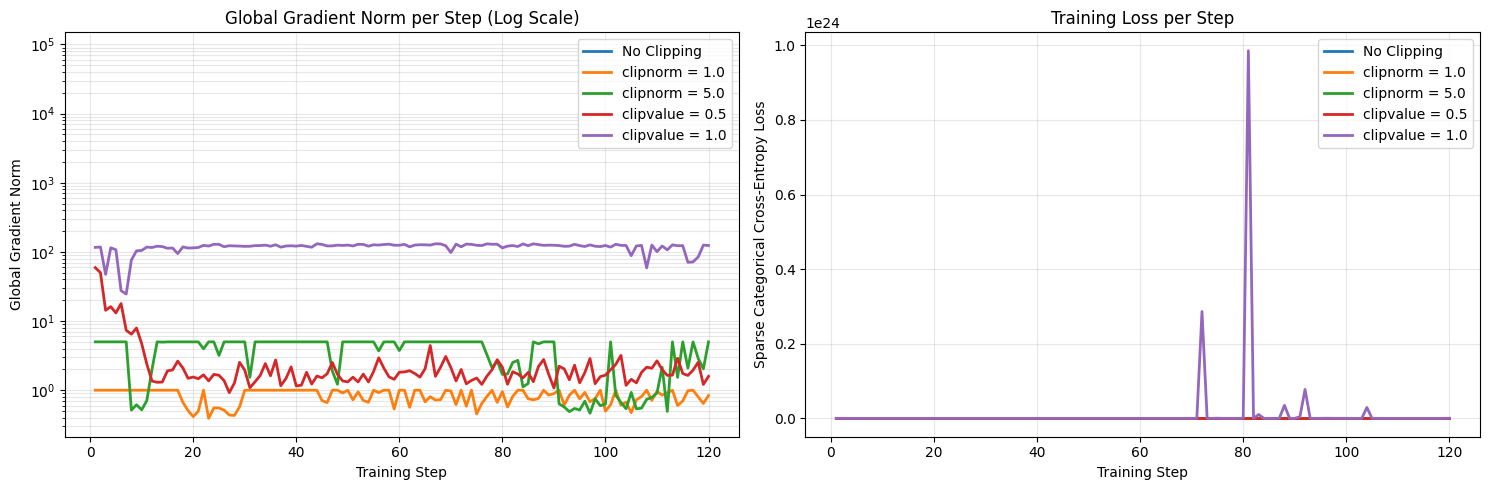


=== Recommendation ===
Use `clipnorm = 1.0` (or between 1.0 and 5.0) as the default clipping threshold:
- Unlike `clipvalue`, which clips each coordinate independently and can distort the gradient direction,
  `clipnorm` scales the entire gradient vector uniformly, preserving the true descent direction.
- `clipnorm = 1.0` eliminates gradient spikes and NaN divergence while maintaining smooth, steady loss reduction.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Character-Level Text Corpus Preparation
# ==========================================
text = (
    "Deep learning models learn sequential patterns from character streams. "
    "When recurrent neural networks process long text sequences with a high learning rate, "
    "repeated matrix multiplications can cause gradients to explode and losses to become NaN. "
    "Gradient clipping stabilizes training by capping the gradient norm or individual values. "
) * 20

chars = sorted(list(set(text)))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
encoded = np.array([char_to_idx[c] for c in text], dtype=np.int32)

SEQ_LEN = 30
X_list, y_list = [], []
for i in range(0, len(encoded) - SEQ_LEN, 3):
    X_list.append(encoded[i : i + SEQ_LEN])
    y_list.append(encoded[i + SEQ_LEN])

X_data = np.array(X_list)
y_data = np.array(y_list)
dataset = tf.data.Dataset.from_tensor_slices((X_data, y_data)).shuffle(500, seed=42).batch(32)

print(f"Corpus length: {len(text)} | Vocab size: {vocab_size} | Sequences: {len(X_data)}\n")

# ==========================================
# Model Builder (ReLU SimpleRNN + High LR to Expose Exploding Gradients)
# ==========================================
def build_char_rnn():
    tf.random.set_seed(42)
    return keras.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(vocab_size, 16),
        layers.SimpleRNN(
            64,
            activation="relu",
            recurrent_initializer=keras.initializers.RandomNormal(stddev=0.25, seed=42)
        ),
        layers.Dense(vocab_size)
    ])

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# ==========================================
# Task 1, 2 & 3: Training Loop with Gradient Norm Logging & Clipping
# ==========================================
def train_rnn(clip_mode=None, threshold=None, lr=0.25, max_steps=120):
    model = build_char_rnn()
    optimizer = keras.optimizers.SGD(learning_rate=lr)

    losses, grad_norms = [], []
    spike_step, nan_step = None, None
    step = 0

    for epoch in range(20):
        for x_batch, y_batch in dataset:
            step += 1
            with tf.GradientTape() as tape:
                logits = model(x_batch, training=True)
                loss = loss_fn(y_batch, logits)

            grads = tape.gradient(loss, model.trainable_variables)

            # Apply requested clipping strategy
            if clip_mode == "clipnorm":
                grads, _ = tf.clip_by_global_norm(grads, threshold)
            elif clip_mode == "clipvalue":
                grads = [tf.clip_by_value(g, -threshold, threshold) for g in grads]

            g_norm = float(tf.linalg.global_norm(grads).numpy())
            loss_val = float(loss.numpy())

            losses.append(loss_val)
            grad_norms.append(g_norm)

            if spike_step is None and (g_norm > 20.0 or np.isnan(g_norm) or np.isinf(g_norm)):
                spike_step = step
            if nan_step is None and (np.isnan(loss_val) or np.isinf(loss_val)):
                nan_step = step
                break

            optimizer.apply_gradients(zip(grads, model.trainable_variables))

            if step >= max_steps:
                break
        if nan_step is not None or step >= max_steps:
            break

    return losses, grad_norms, spike_step, nan_step

# Run all configurations
configs = [
    ("No Clipping",       None,        None),
    ("clipnorm = 1.0",    "clipnorm",  1.0),
    ("clipnorm = 5.0",    "clipnorm",  5.0),
    ("clipvalue = 0.5",   "clipvalue", 0.5),
    ("clipvalue = 1.0",   "clipvalue", 1.0),
]

results = {}
print("=== Training Summary Across Clipping Settings (LR = 0.25) ===")
for name, mode, thresh in configs:
    losses, norms, spike, nan = train_rnn(clip_mode=mode, threshold=thresh)
    results[name] = (losses, norms)
    final_loss = f"{losses[-1]:.4f}" if not np.isnan(losses[-1]) else "NaN"
    print(f"{name:16s} | Steps: {len(losses):3d} | Spike Step: {str(spike):4s} | NaN Step: {str(nan):4s} | Final Loss: {final_loss}")

# ==========================================
# Task 4: Plot Gradient Norm & Loss Curves
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, (losses, norms) in results.items():
    steps = np.arange(1, len(losses) + 1)
    axes[0].plot(steps, norms, linewidth=2, label=name)
    axes[1].plot(steps, losses, linewidth=2, label=name)

axes[0].set_yscale("log")
axes[0].set_title("Global Gradient Norm per Step (Log Scale)")
axes[0].set_xlabel("Training Step")
axes[0].set_ylabel("Global Gradient Norm")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

axes[1].set_title("Training Loss per Step")
axes[1].set_xlabel("Training Step")
axes[1].set_ylabel("Sparse Categorical Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Recommendation
# ==========================================
print("""
=== Recommendation ===
Use `clipnorm = 1.0` (or between 1.0 and 5.0) as the default clipping threshold:
- Unlike `clipvalue`, which clips each coordinate independently and can distort the gradient direction,
  `clipnorm` scales the entire gradient vector uniformly, preserving the true descent direction.
- `clipnorm = 1.0` eliminates gradient spikes and NaN divergence while maintaining smooth, steady loss reduction.
""")
